# Exploring the geography (ISTAT) and the cost of a mortgage (ECB)

The last exploration notebook. It looks at the two sources that **connect** the others:

- **ISTAT list of comuni**: the official 6-digit code, name, region and macro-area of
  every comune. It is the "master list" that MEF and OMI are matched against.
- **ISTAT boundaries**: the shape of every comune, to draw maps and measure distances.
- **ECB mortgage rates**: the average interest rate on new home loans in Italy, month by
  month, to turn a house price into a **monthly mortgage payment**.

1. Download the files
2. The list of comuni
3. Do the codes match? (MEF and OMI vs ISTAT)
4. Boundaries: first maps and distances (scipy)
5. Mortgage rates 2014 → 2024
6. Insight: the monthly mortgage payment in Milan, 2014 vs 2024

⚠️ I wrote this notebook without seeing your files. Cells marked **CHECK** print
something you should look at before trusting the next cells.

In [1]:
import re
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.spatial import cKDTree

# The notebook runs from notebooks/, so the project root is one level up
base_dir = Path.cwd().parent
istat_raw_dir = base_dir / "data" / "raw" / "istat"
ecb_raw_dir = base_dir / "data" / "raw" / "ecb"
mef_raw_dir = base_dir / "data" / "raw" / "mef"
omi_raw_dir = base_dir / "data" / "raw" / "omi"

MILAN_CODE = "015146"
FLAT_SIZE_M2 = 70          # same "typical flat" as in the OMI notebook

## 1. Download the files

All three sources are direct links with no login, so the code can download them
(the OMI files needed SPID, so those were downloaded by hand).

**The ECB Data Portal has an API**: a URL that returns data instead of a web page.
The part after `MIR/` is the **series key**, the name of one time series:

| Part | Meaning |
|------|---------|
| `M` | monthly |
| `IT` | Italy |
| `B` | banks' interest rate statistics |
| `A2C` | loans to households **for house purchase** |
| `AM` | all maturities, combined into one indicator |
| `R` | interest rate |
| `A` | new business (new loans in that month, not old ones) |
| `2250` | lent to households |
| `EUR` | in euro |

This series is the **composite cost of borrowing** for house purchase: the average rate
on new mortgages (fixed and variable together), weighted by volume.

In [2]:
ISTAT_COMUNI_URL = (
    "https://www.istat.it/storage/codici-unita-amministrative/"
    "Elenco-comuni-italiani.xlsx"
)
ISTAT_BOUNDARIES_URL = (
    "https://www.istat.it/storage/cartografia/confini_amministrativi/"
    "generalizzati/2025/Limiti01012025_g.zip"
)
MORTGAGE_SERIES = "M.IT.B.A2C.AM.R.A.2250.EUR.N"
ECB_URL = (
    "https://data-api.ecb.europa.eu/service/data/MIR/"
    f"{MORTGAGE_SERIES}?format=csvdata&startPeriod=2010-01"
)

comuni_path = istat_raw_dir / "Elenco-comuni-italiani.xlsx"
boundaries_zip = istat_raw_dir / "Limiti01012025_g.zip"
mortgage_path = ecb_raw_dir / "mortgage_rate_it.csv"


def download_if_missing(url, path):
    """
    Download a file once; later calls use the copy on disk (a cache).

    Parameters
    ----------
    url : str
        Where to download from.
    path : pathlib.Path
        Where to save the file.

    Returns
    -------
    pathlib.Path
        The path of the file on disk.
    """
    if path.exists():
        print(f"{path.name}: already downloaded")
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {path.name} ...")
    # Some public servers refuse requests without a browser-like "User-Agent"
    response = requests.get(url, timeout=120, headers={"User-Agent": "Mozilla/5.0"})
    response.raise_for_status()                   # 404, 500, ... become an error
    path.write_bytes(response.content)
    print(f"  saved to {path.relative_to(base_dir)} ({len(response.content) / 1e6:.1f} MB)")
    return path


download_if_missing(ISTAT_COMUNI_URL, comuni_path)
download_if_missing(ISTAT_BOUNDARIES_URL, boundaries_zip)
download_if_missing(ECB_URL, mortgage_path)

# Unzip the boundaries into their own folder (once)
boundaries_dir = istat_raw_dir / boundaries_zip.stem
if not boundaries_dir.exists():
    with zipfile.ZipFile(boundaries_zip) as z:
        z.extractall(boundaries_dir)
    print(f"Extracted to {boundaries_dir.relative_to(base_dir)}")

Elenco-comuni-italiani.xlsx: already downloaded
Limiti01012025_g.zip: already downloaded
mortgage_rate_it.csv: already downloaded


## 2. The list of comuni

The Excel file has long Italian column names, some with line breaks inside
(e.g. `"Codice dell'Unità territoriale sovracomunale \n(valida a fini statistici)"`).
Instead of copying them by hand, we find each column by a piece of its name.

In [3]:
# dtype=str: read everything as text, so "001001" keeps its leading zeros
comuni_raw = pd.read_excel(comuni_path, dtype=str)

# CHECK: the column names, exactly as they are in the file
print(comuni_raw.shape)
for col in comuni_raw.columns:
    print(repr(col))

(7894, 27)
'Codice Regione'
"Codice dell'Unità territoriale sovracomunale \n(valida a fini statistici)"
'Codice Provincia (Storico)(1)'
'Progressivo del Comune (2)'
'Codice Comune formato alfanumerico'
'Denominazione (Italiana e straniera)'
'Denominazione in italiano'
'Denominazione altra lingua'
'Codice Ripartizione Geografica'
'Ripartizione geografica'
'Denominazione Regione'
"Denominazione dell'Unità territoriale sovracomunale \n(valida a fini statistici)"
'Tipologia di Unità territoriale sovracomunale '
'Flag Comune capoluogo di Provincia/Città metropolitana/libero consorzio'
'Sigla automobilistica'
'Codice Comune formato numerico'
'Codice Comune numerico con 107 Province (dal 2017 al 2025)'
'Codice Comune numerico con 110 Province (dal 2010 al 2016)'
'Codice Comune numerico con 107 Province (dal 2006 al 2009)'
'Codice Comune numerico con 103 Province (dal 1995 al 2005)'
'Codice Catastale del Comune'
'Codice NUTS1 2021'
'Codice NUTS2 2021 (3) '
'Codice NUTS3 2021'
'Codice NUTS1 202

In [4]:
def find_istat_column(df, text, exclude=None):
    """
    Find the one column whose name contains a piece of text.

    Line breaks and double spaces in the names are ignored, and so is upper/lower case.

    Parameters
    ----------
    df : pandas.DataFrame
        The ISTAT table.
    text : str
        A piece of the column name, e.g. ``"alfanumerico"``.
    exclude : str, optional
        Skip columns that also contain this text (e.g. ``"codice"``, to get the name of
        the macro-area and not its code).

    Returns
    -------
    str
        The full, original column name.

    Raises
    ------
    KeyError
        If no column, or more than one column, matches.
    """
    matches = []
    for col in df.columns:
        clean = " ".join(str(col).split()).lower()      # one space, lower case
        if text.lower() in clean and not (exclude and exclude.lower() in clean):
            matches.append(col)
    if len(matches) != 1:
        raise KeyError(f"Expected 1 column containing {text!r}, found {matches}")
    return matches[0]


# Keep only what we need, with short English names
ISTAT_COLUMNS = {
    "istat_code": find_istat_column(comuni_raw, "comune formato alfanumerico"),
    "name": find_istat_column(comuni_raw, "denominazione in italiano"),
    "province": find_istat_column(comuni_raw, "sigla automobilistica"),
    "region": find_istat_column(comuni_raw, "denominazione regione"),
    "macro_area": find_istat_column(comuni_raw, "ripartizione geografica", exclude="codice"),
    "is_capital": find_istat_column(comuni_raw, "capoluogo"),
}
comuni = comuni_raw[list(ISTAT_COLUMNS.values())].copy()
comuni.columns = list(ISTAT_COLUMNS.keys())
comuni["istat_code"] = comuni["istat_code"].str.strip().str.zfill(6)
comuni["is_capital"] = comuni["is_capital"].str.strip() == "1"   # "1" = provincial capital

comuni.head()

,istat_code,name,province,region,macro_area,is_capital
0,001001,Agliè,TO,Piemonte,Nord-ovest,False
1,001002,Airasca,TO,Piemonte,Nord-ovest,False
2,001003,Ala di Stura,TO,Piemonte,Nord-ovest,False
3,001004,Albiano d'Ivrea,TO,Piemonte,Nord-ovest,False
4,001006,Almese,TO,Piemonte,Nord-ovest,False


In [5]:
# Checks: one row per comune, every code has 6 digits, no missing values
print("comuni:", len(comuni))
print("codes unique:", comuni["istat_code"].is_unique)
print("all codes have 6 digits:", comuni["istat_code"].str.fullmatch(r"\d{6}").all())
print("missing values:", comuni.isna().sum().sum())
print("provincial capitals:", comuni["is_capital"].sum())
print()
print(comuni["macro_area"].value_counts())
print()
print(comuni[comuni["istat_code"] == MILAN_CODE])

comuni: 7894
codes unique: True
all codes have 6 digits: True
missing values: 93
provincial capitals: 119

macro_area
Nord-ovest    2989
Sud           1783
Nord-est      1386
Centro         968
Isole          768
Name: count, dtype: int64

     istat_code    name province     region  macro_area  is_capital
1771     015146  Milano       MI  Lombardia  Nord-ovest        True


**Why this file matters:**
- It has **proper names** with accents and apostrophes ("Cortina d'Ampezzo"), while MEF
  has upper case without accents and OMI uses a backtick. We use ISTAT names for display.
- It has the **macro-area** (Nord-ovest, Nord-est, Centro, Sud, Isole), which we need to
  compare North and South in the analysis.

## 3. Do the codes match?

The whole project depends on joining MEF, OMI and ISTAT on the 6-digit code.
We load **only the codes** from each source and compare them with the ISTAT list.
(These few loading lines are copied from notebooks 01 and 02. In the `affordability`
package they will be one function each, used everywhere.)

In [6]:
# MEF: code and name, for 2014 and 2024
mef_codes = {}
for year in [2014, 2024]:
    mef = pd.read_csv(
        mef_raw_dir / f"mef_income_{year}.csv", sep=";", encoding="latin-1",
        usecols=["Codice Istat Comune", "Denominazione Comune"],
        dtype=str, keep_default_na=False, na_values=[""],
    )
    mef = mef[mef["Codice Istat Comune"].str.fullmatch(r"\d{6}")]   # drop the "0" row
    mef_codes[year] = mef.set_index("Codice Istat Comune")["Denominazione Comune"]


# OMI: the codes in the VALORI files (same reading rules as notebook 02)
def find_header_row(path, marker="Zona", max_lines=10):
    """Return the 0-based number of the line that contains the column names."""
    with open(path, encoding="latin-1") as f:
        for i, line in enumerate(f):
            if i >= max_lines:
                break
            if marker in line.split(";"):
                return i
    raise ValueError(f"No header with {marker!r} in the first {max_lines} lines of {path.name}")


omi_codes = {}
omi_valori = {}
for path in sorted(omi_raw_dir.rglob("*VALORI*.csv")):
    year = re.search(r"(20\d\d)[12](?:\D|$)", path.name).group(1)
    df = pd.read_csv(path, sep=";", encoding="latin-1", skiprows=find_header_row(path),
                     dtype=str, keep_default_na=False, na_values=[""])
    df["istat_code"] = (df["Comune_ISTAT"].str.replace(r"\D", "", regex=True)
                        .str[-6:].str.zfill(6))
    omi_valori[int(year)] = df
    omi_codes[int(year)] = (df.dropna(subset=["Comune_ISTAT"])
                            .drop_duplicates("istat_code")
                            .set_index("istat_code")["Comune_descrizione"])

print("MEF years:", sorted(mef_codes), " OMI years:", sorted(omi_codes))

MEF years: [2014, 2024]  OMI years: [2014, 2024]


In [7]:
istat_set = set(comuni["istat_code"])


def compare_with_istat(codes, label):
    """
    Print how many codes of a source are in the ISTAT list, and return the others.

    Parameters
    ----------
    codes : pandas.Series
        Index = 6-digit codes, values = names in that source.
    label : str
        Name of the source, for the printout.

    Returns
    -------
    pandas.Series
        The codes (and names) that are NOT in the ISTAT list.
    """
    not_found = codes[~codes.index.isin(istat_set)]
    share = (1 - len(not_found) / len(codes)) * 100
    print(f"{label:<9} {len(codes):>5} comuni, {share:5.1f}% in the ISTAT 2025 list, "
          f"{len(not_found):>4} not found")
    return not_found


missing = {}
for year, codes in mef_codes.items():
    missing[f"MEF {year}"] = compare_with_istat(codes, f"MEF {year}")
for year, codes in omi_codes.items():
    missing[f"OMI {year}"] = compare_with_istat(codes, f"OMI {year}")

# The other direction: comuni in ISTAT that MEF 2024 does not have
new_in_istat = comuni[~comuni["istat_code"].isin(mef_codes[2024].index)]
print(f"\nIn ISTAT 2025 but not in MEF 2024: {len(new_in_istat)}")
print(new_in_istat[["istat_code", "name", "region"]].head(15).to_string(index=False))

MEF 2014   8048 comuni,  92.2% in the ISTAT 2025 list,  626 not found
MEF 2024   7896 comuni,  95.2% in the ISTAT 2025 list,  380 not found
OMI 2014   8075 comuni,  90.2% in the ISTAT 2025 list,  790 not found
OMI 2024   7888 comuni,  93.6% in the ISTAT 2025 list,  504 not found

In ISTAT 2025 but not in MEF 2024: 378
istat_code             name   region
    024129 Castegnero Nanto   Veneto
    112001          Alghero Sardegna
    112002            Anela Sardegna
    112003           Ardara Sardegna
    112004           Banari Sardegna
    112005        Benetutti Sardegna
    112006          Bessude Sardegna
    112007        Bonnanaro Sardegna
    112008             Bono Sardegna
    112009          Bonorva Sardegna
    112010          Borutta Sardegna
    112011         Bottidda Sardegna
    112012           Bultei Sardegna
    112013            Bulzi Sardegna
    112014           Burgos Sardegna


In [8]:
# CHECK: which comuni are not found? Look at the names.
for label, not_found in missing.items():
    print(f"===== {label}: {len(not_found)} not in the ISTAT list =====")
    print(not_found.head(15).to_string())
    print()

===== MEF 2014: 626 not in the ISTAT list =====
Codice Istat Comune
095001             ABBASANTA
047001               ABETONE
043001           ACQUACANINA
075001    ACQUARICA DEL CAPO
104001                AGGIUS
095002          AIDOMAGGIORE
104003        ALA' DEI SARDI
025002        ALANO DI PIAVE
095003             ALBAGIARA
018002    ALBAREDO ARNABOLDI
095004                  ALES
090003               ALGHERO
001005       ALICE SUPERIORE
095005                 ALLAI
006006     ALLUVIONI CAMBIO'

===== MEF 2024: 380 not in the ISTAT list =====
Codice Istat Comune
095001                 ABBASANTA
090001                    AGGIUS
095002              AIDOMAGGIORE
090002            ALA' DEI SARDI
095003                 ALBAGIARA
095004                      ALES
090003                   ALGHERO
095005                     ALLAI
090004                     ANELA
091095                  TORTOLI'
095006                   ARBOREA
111001                     ARBUS
095046    SAN NICOLO' D'ARCIDANO

**How to read this (what I expect you will see):**

- **Mergers (*fusioni*)**: Italy had about 8,050 comuni in 2014 and about 7,900 in 2025.
  Small comuni keep merging into new ones (e.g. several villages become one), and the new
  comune gets a **new code**, while the old codes disappear. So most "not found" rows in
  **2014** should be old comuni that no longer exist. This also explains why some comuni
  look like they "grew" or "shrank" between 2014 and 2024 (remember Mappano).
- **2024 data vs the 2025 list**: a few mergers happened on 1 January 2025, so even MEF 2024
  may have a handful of codes that ISTAT 2025 no longer lists, and ISTAT has the new ones.
- **OMI**: if codes are not found, check the odd short codes from notebook 02.

**Decision for the analysis:** compare 2014 and 2024 **only for comuni that exist with
the same code in both years** (and pass the ±50% size filter). Mapping old comuni to new
ones is possible with ISTAT's list of administrative changes, but for a few small comuni
it is not worth the complexity. Write the counts in the README.

## 4. Boundaries: first maps and distances

The ZIP contains **shapefiles**: a format for maps made of several files with the same
name (`.shp` the shapes, `.dbf` the table, `.prj` the coordinate system, ...).
`geopandas` reads them into a **GeoDataFrame**: a DataFrame with a `geometry` column.

There are boundaries for regions, provinces and comuni. We want the comuni, in the
version with `WGS84` in the name.

In [9]:
# CHECK: the shapefiles in the folder
for path in sorted(boundaries_dir.rglob("*.shp")):
    print(path.relative_to(boundaries_dir))

Com01012025_g/Com01012025_g_WGS84.shp
ProvCM01012025_g/ProvCM01012025_g_WGS84.shp
Reg01012025_g/Reg01012025_g_WGS84.shp
RipGeo01012025_g/RipGeo01012025_g_WGS84.shp


In [10]:
comuni_shp = sorted(boundaries_dir.rglob("Com*_WGS84.shp"))[0]
geo = gpd.read_file(comuni_shp)

# CHECK: columns, coordinate system, size
print(geo.shape)
print(geo.columns.tolist())
print("CRS:", geo.crs)
geo.head(3)

(7896, 13)
['COD_RIP', 'COD_REG', 'COD_PROV', 'COD_CM', 'COD_UTS', 'PRO_COM', 'PRO_COM_T', 'COMUNE', 'COMUNE_A', 'CC_UTS', 'Shape_Leng', 'Shape_Area', 'geometry']
CRS: EPSG:32632


,COD_RIP,COD_REG,COD_PROV,COD_CM,COD_UTS,PRO_COM,PRO_COM_T,COMUNE,COMUNE_A,CC_UTS,Shape_Leng,Shape_Area,geometry
0,1,1,1,201,201,1001,001001,AgliÃ¨,NaN,0,15843.982391,1.324068e+07,"POLYGON ((405359.557 5026575.657, 405225.558 5..."
1,1,1,1,201,201,1002,001002,Airasca,NaN,0,16188.945217,1.603272e+07,"POLYGON ((381549.965 4977201.02, 382134.057 49..."
2,1,1,1,201,201,1003,001003,Ala di Stura,NaN,0,29257.735299,4.617495e+07,"POLYGON ((365491.663 5022162.177, 366292.255 5..."


- `PRO_COM_T` is the 6-digit code **as text** (`PRO_COM` is the same code as a number,
  without the leading zeros). We join on `PRO_COM_T`.
- The **CRS** (coordinate reference system) should be **EPSG:32632** (UTM zone 32N).
  Its coordinates are in **metres**, not degrees, so distances and areas can be measured
  directly. That is why we do not convert to latitude/longitude.

boundaries without a match in the ISTAT list: 381


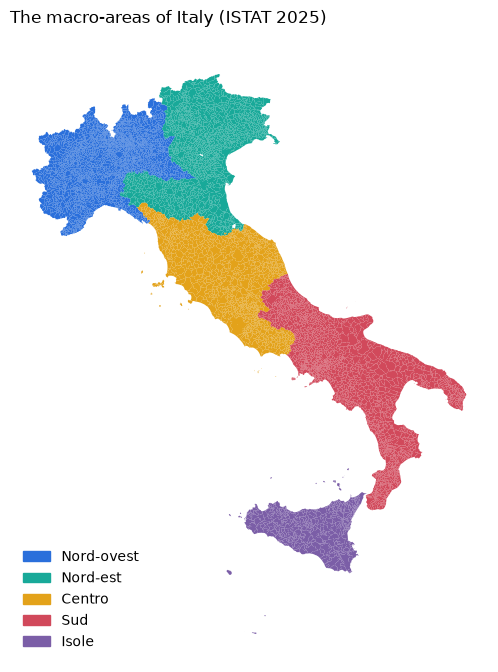

In [11]:
geo = geo.rename(columns={"PRO_COM_T": "istat_code"})[["istat_code", "geometry"]]
geo = geo.merge(comuni, on="istat_code", how="left", validate="one_to_one")
print("boundaries without a match in the ISTAT list:", geo["name"].isna().sum())

# Map 1: the five macro-areas, to check that the join and the map work
AREA_COLORS = {"Nord-ovest": "#2a6fdb", "Nord-est": "#18a999", "Centro": "#e3a21a",
               "Sud": "#d1495b", "Isole": "#7b5ea7"}
fig, ax = plt.subplots(figsize=(7, 8))
for area, color in AREA_COLORS.items():
    geo[geo["macro_area"] == area].plot(ax=ax, color=color, linewidth=0, label=area)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in AREA_COLORS.values()],
          labels=list(AREA_COLORS), loc="lower left", frameon=False)
ax.set_title("The macro-areas of Italy (ISTAT 2025)", loc="left")
ax.set_axis_off()
plt.show()

### A first real map: average taxable income per comune (MEF 2024)

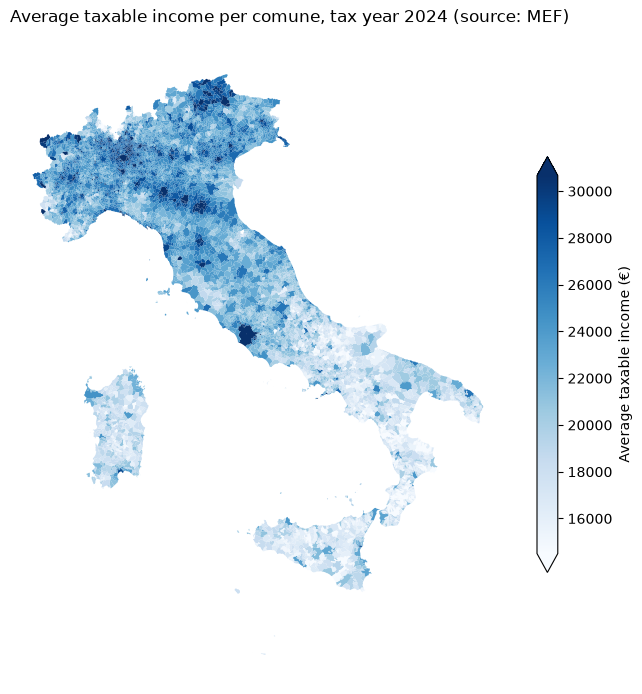

In [12]:
mef_2024 = pd.read_csv(mef_raw_dir / "mef_income_2024.csv", sep=";", encoding="latin-1",
                       dtype={"Codice Istat Comune": str},
                       keep_default_na=False, na_values=[""])
mef_2024.columns = [" ".join(c.split()).replace(" in euro", "") for c in mef_2024.columns]
mef_2024["mean_income"] = (mef_2024["Reddito imponibile - Ammontare"]
                           / mef_2024["Reddito imponibile - Frequenza"])

geo_income = geo.merge(mef_2024[["Codice Istat Comune", "mean_income"]],
                       left_on="istat_code", right_on="Codice Istat Comune", how="left")

# Colour scale from the 2nd to the 98th percentile, so a few extreme comuni
# (Campione d'Italia, Lajatico, ...) do not wash out all the others
low, high = geo_income["mean_income"].quantile([0.02, 0.98])
fig, ax = plt.subplots(figsize=(8, 9))
geo_income.plot(column="mean_income", cmap="Blues", vmin=low, vmax=high, linewidth=0,
                ax=ax, legend=True,
                legend_kwds={"label": "Average taxable income (€)", "shrink": 0.6},
                missing_kwds={"color": "#dddddd", "label": "no data"})
ax.set_title("Average taxable income per comune, tax year 2024 (source: MEF)", loc="left")
ax.set_axis_off()
plt.show()

The North/South divide and the rich areas around Milan, Bologna and the Alpine valleys
should be clearly visible. Grey comuni = no MEF data for that code (see section 3).
This is the base for the main maps of the project: years of income to buy a home, Gini.

### Distances: who lives "near Milan"? (scipy)

For the Milan case study we need the distance of every comune from Milan.
Each comune becomes one point (its **centroid**, the centre of its shape). Then a
**k-d tree** from `scipy.spatial` finds neighbours fast: instead of comparing every point
with every other point, it splits the space into boxes, like a phone book sorted by name.

In [13]:
# Centroids in metres (the CRS is already metric)
centroids = np.column_stack([geo.geometry.centroid.x, geo.geometry.centroid.y])
tree = cKDTree(centroids)

milan_idx = geo.index[geo["istat_code"] == MILAN_CODE][0]
milan_xy = centroids[milan_idx]

# Distance of every comune from Milan, in km (numpy, vectorised)
geo["dist_milan_km"] = np.hypot(*(centroids - milan_xy).T) / 1000

# The 10 nearest comuni (k=11 because the nearest one is Milan itself)
dist, idx = tree.query(milan_xy, k=11)
print("Nearest comuni to Milan:")
print(geo.iloc[idx[1:]][["name", "province", "dist_milan_km"]]
      .round(1).to_string(index=False))

# All comuni within 30 km
within_30km = tree.query_ball_point(milan_xy, r=30_000)
print(f"\nComuni within 30 km of Milan: {len(within_30km)}")

Nearest comuni to Milan:
           name province  dist_milan_km
        Corsico       MI            6.8
 Cesano Boscone       MI            7.4
Novate Milanese       MI            7.5
         Bresso       MI            7.8
         Assago       MI            7.9
      Baranzate       MI            8.2
        Cormano       MI            8.4
     Buccinasco       MI            8.4
           Pero       MI            8.9
        Segrate       MI            9.0

Comuni within 30 km of Milan: 262


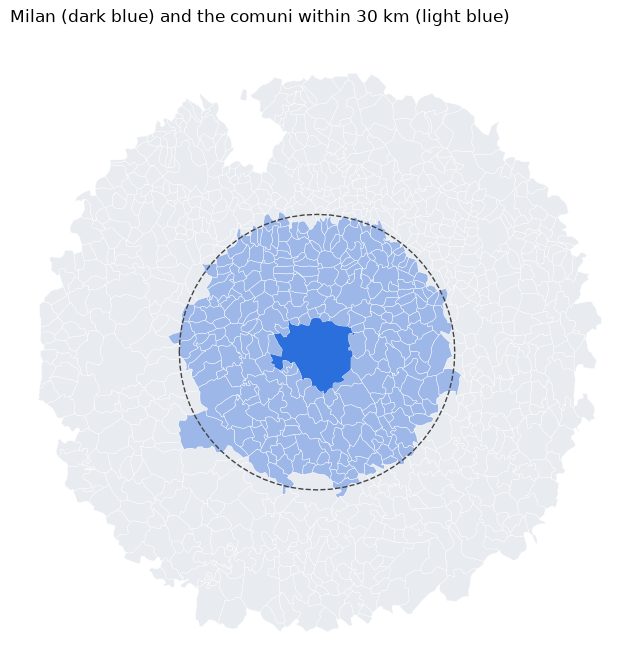

In [14]:
# Map of the Milan area, with the 30 km ring
milan_area = geo[geo["dist_milan_km"] <= 60]
ring = gpd.GeoSeries([geo.loc[milan_idx, "geometry"].centroid.buffer(30_000)], crs=geo.crs)

fig, ax = plt.subplots(figsize=(8, 8))
milan_area.plot(ax=ax, color="#e8ebf0", edgecolor="white", linewidth=0.3)
geo.iloc[within_30km].plot(ax=ax, color="#9db8e8", edgecolor="white", linewidth=0.3)
geo.loc[[milan_idx]].plot(ax=ax, color="#2a6fdb")
ring.boundary.plot(ax=ax, color="#444", linewidth=1, linestyle="--")
ax.set_title("Milan (dark blue) and the comuni within 30 km (light blue)", loc="left")
ax.set_axis_off()
plt.show()

## 5. Mortgage rates 2014 → 2024 (ECB)

In [15]:
rates_raw = pd.read_csv(mortgage_path)

# CHECK: the ECB file has many columns; TITLE says which series we got
print(rates_raw.columns.tolist())
if "TITLE" in rates_raw.columns:
    print(rates_raw["TITLE"].iloc[0])

rates = pd.DataFrame({
    "date": pd.to_datetime(rates_raw["TIME_PERIOD"], format="%Y-%m"),
    "rate": pd.to_numeric(rates_raw["OBS_VALUE"], errors="coerce"),   # % per year
}).dropna().sort_values("date")
print(rates.tail())

['KEY', 'FREQ', 'REF_AREA', 'BS_REP_SECTOR', 'BS_ITEM', 'MATURITY_NOT_IRATE', 'DATA_TYPE_MIR', 'AMOUNT_CAT', 'BS_COUNT_SECTOR', 'CURRENCY_TRANS', 'IR_BUS_COV', 'TIME_PERIOD', 'OBS_VALUE', 'OBS_STATUS', 'OBS_CONF', 'OBS_PRE_BREAK', 'OBS_COM', 'TIME_FORMAT', 'BREAKS', 'COLLECTION', 'COMPILING_ORG', 'DISS_ORG', 'DOM_SER_IDS', 'PUBL_ECB', 'PUBL_MU', 'PUBL_PUBLIC', 'UNIT_INDEX_BASE', 'COMPILATION', 'COVERAGE', 'DECIMALS', 'NAT_TITLE', 'SOURCE_AGENCY', 'TITLE', 'TITLE_COMPL', 'UNIT', 'UNIT_MULT']
Cost of borrowing for households for house purchase
          date  rate
196 2026-05-01  3.54
197 2026-06-01  3.54
198 2026-07-01  3.49
199 2026-08-01  3.58
200 2026-09-01  3.61


Average mortgage rate 2014: 3.20%   2024: 3.82%
Lowest month: Dec 2020 (1.25%)


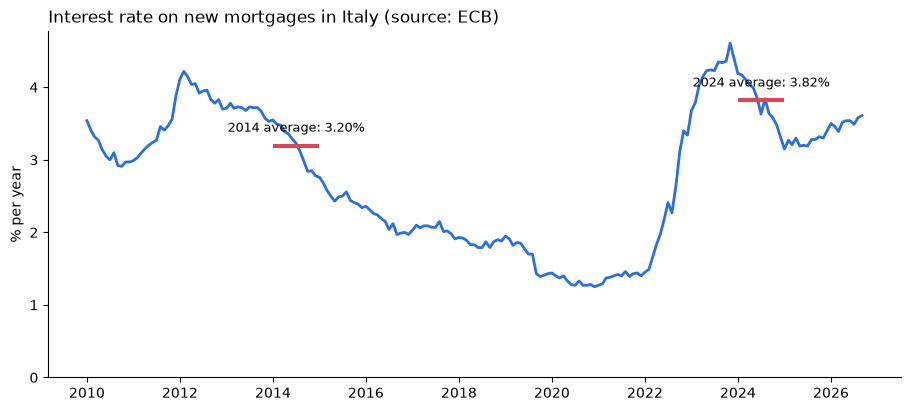

In [16]:
# Yearly averages: the same calendar years as the MEF tax years
yearly_rate = rates.groupby(rates["date"].dt.year)["rate"].mean()
RATE_2014 = yearly_rate.loc[2014]
RATE_2024 = yearly_rate.loc[2024]
print(f"Average mortgage rate 2014: {RATE_2014:.2f}%   2024: {RATE_2024:.2f}%")
print(f"Lowest month: {rates.loc[rates['rate'].idxmin(), 'date']:%b %Y} "
      f"({rates['rate'].min():.2f}%)")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(rates["date"], rates["rate"], color="#2a6fdb", linewidth=2)
for year, value in [(2014, RATE_2014), (2024, RATE_2024)]:
    ax.hlines(value, pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year}-12-31"),
              color="#d1495b", linewidth=3)
    ax.annotate(f"{year} average: {value:.2f}%", (pd.Timestamp(f"{year}-07-01"), value),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9)
ax.set_ylabel("% per year")
ax.set_ylim(bottom=0)
ax.set_title("Interest rate on new mortgages in Italy (source: ECB)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**The story of the decade:** rates fell from 2014 to record lows around 2020–2021
(the ECB's negative rates and bond buying), then jumped in 2022–2023 when the ECB raised
rates to fight inflation. So 2014 and 2024 may look similar, but **2021 was a very cheap
moment to borrow**. Many people bought then, which pushed prices up; the buyers of 2024
pay the high prices **and** higher rates.

## 6. Insight: the monthly mortgage payment in Milan, 2014 vs 2024

A bank lends a share of the price (the **loan-to-value**, here 80%) and you pay it back
in equal monthly payments. The payment comes from the **annuity formula**:

$$\text{payment} = P \cdot \frac{r}{1 - (1 + r)^{-n}}$$

where $P$ is the loan, $r$ the **monthly** rate (yearly rate / 12) and $n$ the number of
months. If the rate is 0 the formula divides by zero, and the payment is simply $P / n$.

Banks usually refuse a mortgage if the payment is more than **30–35% of net income**.

In [17]:
LOAN_TO_VALUE = 0.80
MORTGAGE_YEARS = 25


def mortgage_payment(principal, annual_rate_pct, years=MORTGAGE_YEARS):
    """
    Monthly payment of a fixed-rate mortgage (annuity formula).

    Works with single numbers and with numpy arrays (vectorised).

    Parameters
    ----------
    principal : float or numpy.ndarray
        Amount borrowed, in euro.
    annual_rate_pct : float or numpy.ndarray
        Yearly interest rate in percent, e.g. ``3.5``.
    years : int, optional
        Length of the mortgage.

    Returns
    -------
    float or numpy.ndarray
        Monthly payment in euro.
    """
    r = np.asarray(annual_rate_pct, dtype=float) / 100 / 12     # monthly rate
    n = years * 12
    # np.where computes both branches, so silence the 0/0 warning of the zero-rate case
    with np.errstate(divide="ignore", invalid="ignore"):
        payment = principal * r / (1 - (1 + r) ** -n)
    return np.where(r == 0, principal / n, payment)


# Quick check with a known value: 100,000 € at 3% for 25 years ≈ 474 €/month
print(f"{float(mortgage_payment(100_000, 3)):.2f}")
print(f"{float(mortgage_payment(100_000, 0)):.2f}   (zero rate: 100,000 / 300)")

474.21
333.33   (zero rate: 100,000 / 300)


In [18]:
# Milan: OMI price (ordinary homes, normal condition, median of the zones; as in notebook 02)
def milan_price(valori):
    """Median zone price (€/m²) of ordinary homes in normal condition in Milan."""
    homes = valori[(valori["istat_code"] == MILAN_CODE)
                   & (valori["Descr_Tipologia"] == "Abitazioni civili")
                   & (valori["Stato"] == "NORMALE")]
    low = pd.to_numeric(homes["Compr_min"].str.replace(",", "."), errors="coerce")
    high = pd.to_numeric(homes["Compr_max"].str.replace(",", "."), errors="coerce")
    return ((low + high) / 2).median()


# Milan: average employee wage per worker (MEF, gross, per year)
def milan_wage(year):
    """Average yearly wage of employees living in Milan (MEF, gross)."""
    mef = pd.read_csv(mef_raw_dir / f"mef_income_{year}.csv", sep=";", encoding="latin-1",
                      dtype={"Codice Istat Comune": str},
                      keep_default_na=False, na_values=[""])
    mef.columns = [" ".join(c.split()).replace(" in euro", "") for c in mef.columns]
    row = mef[mef["Codice Istat Comune"] == MILAN_CODE].iloc[0]
    return (row["Reddito da lavoro dipendente e assimilati - Ammontare"]
            / row["Reddito da lavoro dipendente e assimilati - Frequenza"])


milan = pd.DataFrame({
    "price_m2": [milan_price(omi_valori[2014]), milan_price(omi_valori[2024])],
    "rate_pct": [RATE_2014, RATE_2024],
    "wage_year": [milan_wage(2014), milan_wage(2024)],
}, index=[2014, 2024])
milan["flat_price"] = milan["price_m2"] * FLAT_SIZE_M2
milan["loan"] = milan["flat_price"] * LOAN_TO_VALUE
milan["payment_month"] = mortgage_payment(milan["loan"].to_numpy(), milan["rate_pct"].to_numpy())
milan["share_of_wage_pct"] = milan["payment_month"] / (milan["wage_year"] / 12) * 100
milan.round(1)

,price_m2,rate_pct,wage_year,flat_price,loan,payment_month,share_of_wage_pct
2014,2550.0,3.2,31841.1,178500.0,142800.0,691.9,26.1
2024,3775.0,3.8,38766.1,264250.0,211400.0,1094.8,33.9


### What made it worse: prices, rates or wages?
We change **one thing at a time** from its 2014 value to its 2024 value and keep the
others at 2014. This shows how much each factor alone moves the burden.
(The three effects do not add up exactly, because they multiply each other.)

In [19]:
def burden(price_m2, rate, wage):
    """Mortgage payment as % of the monthly gross wage, for the typical flat."""
    loan = price_m2 * FLAT_SIZE_M2 * LOAN_TO_VALUE
    return float(mortgage_payment(loan, rate)) / (wage / 12) * 100


p14, r14, w14 = milan.loc[2014, ["price_m2", "rate_pct", "wage_year"]]
p24, r24, w24 = milan.loc[2024, ["price_m2", "rate_pct", "wage_year"]]
base = burden(p14, r14, w14)
scenarios = pd.Series({
    "2014 (all 2014 values)": base,
    "only the price changes": burden(p24, r14, w14),
    "only the rate changes": burden(p14, r24, w14),
    "only the wage changes": burden(p14, r14, w24),
    "2024 (all 2024 values)": burden(p24, r24, w24),
})
print((scenarios.round(1).astype(str) + " % of the monthly wage").to_string())

2014 (all 2014 values)    26.1 % of the monthly wage
only the price changes    38.6 % of the monthly wage
only the rate changes     27.9 % of the monthly wage
only the wage changes     21.4 % of the monthly wage
2024 (all 2024 values)    33.9 % of the monthly wage


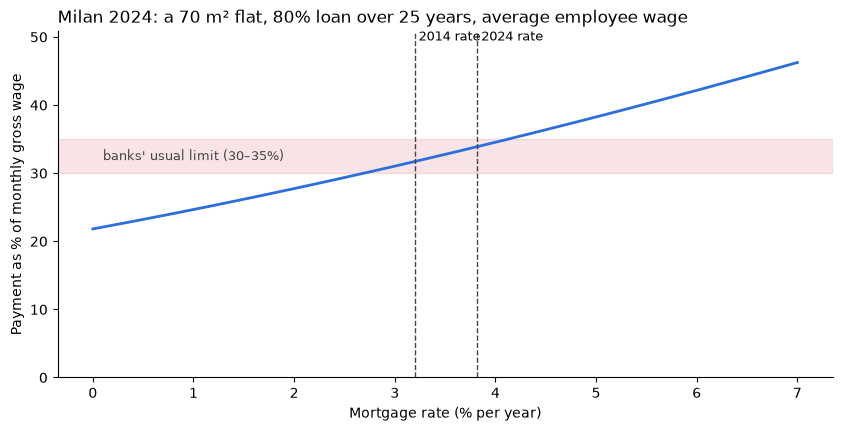

In [20]:
# How sensitive is the 2024 burden to the rate? (numpy: 141 rates at once, no loop)
rate_grid = np.linspace(0, 7, 141)
share_grid = (mortgage_payment(milan.loc[2024, "loan"], rate_grid)
              / (milan.loc[2024, "wage_year"] / 12) * 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rate_grid, share_grid, color="#2a6fdb", linewidth=2)
ax.set_ylim(0, share_grid.max() * 1.1)            # start at 0, so the band is always visible
ax.axhspan(30, 35, color="#d1495b", alpha=0.15)
ax.text(0.1, 32.5, "banks' usual limit (30–35%)", va="center", fontsize=9, color="#444")
for year, rate in [(2014, RATE_2014), (2024, RATE_2024)]:
    ax.axvline(rate, color="#444", linewidth=1, linestyle="--")
    ax.text(rate, ax.get_ylim()[1], f" {year} rate", va="top", fontsize=9)
ax.set_xlabel("Mortgage rate (% per year)")
ax.set_ylabel("Payment as % of monthly gross wage")
ax.set_title(f"Milan 2024: a {FLAT_SIZE_M2} m² flat, 80% loan over {MORTGAGE_YEARS} years, "
             "average employee wage", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**How to read it:** each point is the share of the average Milan wage that would go to
the mortgage at that rate. Where the line is above the red band, a bank would normally
refuse the loan to a single average employee.

**Caveats to keep in mind (and to say on presentation day):**
- MEF wages are **gross** (before tax); banks look at **net** income, which is lower, so
  the real burden is **higher** than shown.
- It assumes one earner. A couple with two incomes halves the share.
- It assumes the buyer has the other 20% (+ taxes and notary fees, ~10% more) in savings,
  which is the hardest part for young workers.
- The rate is the Italian average; a single buyer may get a different one.

## Findings
*(fill in after running the notebook on the real data)*

- Comuni in the ISTAT list: ...; in MEF 2014 / 2024: ... / ...; not found: ... (mergers).
- The ISTAT names and macro-areas join to the boundaries with ... missing.
- Comuni within 30 km of Milan: ...
- Mortgage rate: ...% in 2014, ...% in 2024, lowest in ... (...%).
- Milan, 70 m² flat: the payment went from ...% to ...% of the average wage.
  The main driver was ... .